Task 1: write down equations

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.constants import h, c, k

# Prior bounds （Shape parameters for priors）
Tmin, Tmax = 100.0, 400.0
logfacmin, logfacmax = -30.0, -10.0

bounds = (Tmin, Tmax, logfacmin, logfacmax)


# Planck model in log10 flux
def model(microns, Teff, logfactor):
    lam = np.asarray(microns, dtype=float) * 1e-6
    x = h * c / (lam * k * Teff)

    logflux = (
        logfactor
        + np.log10(2 * h * c**2)
        - 5 * np.log10(lam)
        - np.log(np.expm1(x)) / np.log(10)
    )

    return logflux


# Chi-squared
def chi_squared(lam, logf, errlogf, theta):
    Teff, logfactor = theta
    prediction = model(lam, Teff, logfactor)

    return np.sum(((logf - prediction) / errlogf)**2)


# Gaussian log-likelihood
def log_like(lam, logf, errlogf, theta):
    return -0.5 * chi_squared(lam, logf, errlogf, theta)


# Log-uniform temperature and uniform logfactor priors
def log_prior(theta, bounds):
    Teff, logfactor = theta
    Tmin, Tmax, fmin, fmax = bounds

    if not (Tmin < Teff < Tmax and fmin < logfactor < fmax):
        return -np.inf

    return -np.log(Teff)


# Unnormalized log-posterior
def log_posterior(lam, logf, errlogf, theta, bounds):
    lp = log_prior(theta, bounds)

    if not np.isfinite(lp):
        return -np.inf

    return lp + log_like(lam, logf, errlogf, theta)

Task 2: Import data

In [3]:
# Import observational data
data = np.loadtxt("data.dat", skiprows=7)

lam = data[:, 0]
logf = data[:, 1]
errlogf = data[:, 2]

Task 3: Initialize from a random point

Initial temperature = 150.455 K
Initial logfactor = -19.3883
Chi-squared = 3101.710
Log-likelihood = -1550.855
Log-posterior = -1555.868
Saved: graph/01_Initial_Planck_Model.png


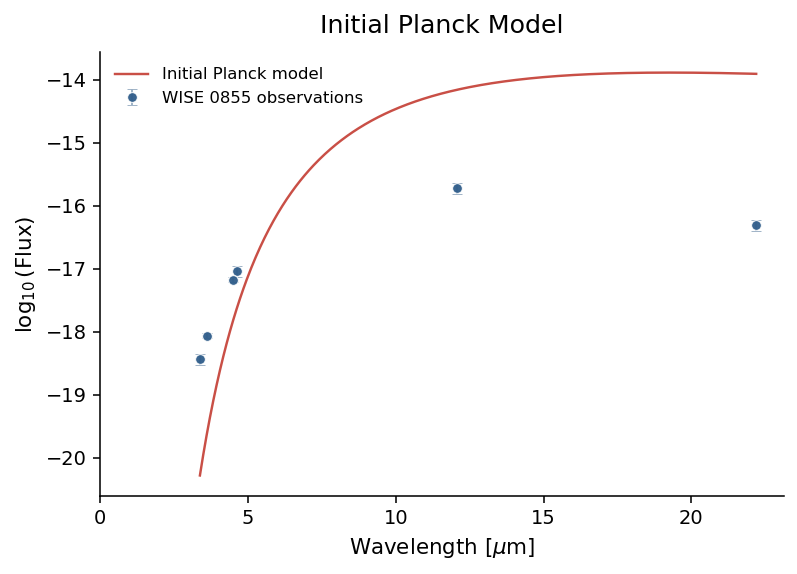

In [5]:
# Random initialization
np.random.seed(17)

T0 = np.exp(np.random.uniform(np.log(Tmin), np.log(Tmax)))
logfactor0 = np.random.uniform(logfacmin, logfacmax)
theta0 = np.array([T0, logfactor0])

# Initial model evaluation
chi2_0 = chi_squared(lam, logf, errlogf, theta0)
loglike_0 = log_like(lam, logf, errlogf, theta0)
logpost_0 = log_posterior(lam, logf, errlogf, theta0, bounds)

print(f"Initial temperature = {T0:.3f} K")
print(f"Initial logfactor = {logfactor0:.4f}")
print(f"Chi-squared = {chi2_0:.3f}")
print(f"Log-likelihood = {loglike_0:.3f}")
print(f"Log-posterior = {logpost_0:.3f}")

# Initial model comparison
lam_grid = np.linspace(lam.min(), lam.max(), 500)
model_grid = model(lam_grid, *theta0)

fig, ax = plt.subplots(figsize=(5.8, 4.2), dpi=140)

ax.errorbar(
    lam, logf, yerr=errlogf,
    fmt='o',
    markersize=5,
    color='#2F5D8A',
    ecolor='#9AAFC4',
    capsize=2.5,
    elinewidth=1,
    markeredgecolor='white',
    markeredgewidth=0.5,
    alpha=0.95,
    label='WISE 0855 observations'
)

ax.plot(
    lam_grid, model_grid,
    color='#C94F46',
    linewidth=1.25,
    label='Initial Planck model'
)

ax.set_xlabel(r'Wavelength [$\mu$m]', fontsize=11)
ax.set_ylabel(r'$\log_{10}(\mathrm{Flux})$', fontsize=11)
ax.set_title('Initial Planck Model', fontsize=13, pad=10)

ax.set_xlim(left=0)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.tick_params(axis='both', labelsize=10)
ax.legend(frameon=False, fontsize=8.5)

plt.tight_layout()
plt.show()


Task 4: Start warlking from this initial point, set up MCMC function

In [6]:
# Set up the MCMC function
def run_mcmc(theta0, lam, logf, errlogf, bounds, jumpsize, jmax):

    theta = np.array(theta0, dtype=float)
    logpost = log_posterior(lam, logf, errlogf, theta, bounds)

    thetachain = [theta.copy()]
    logpostchain = [logpost]

    j = 0
    ntrials = 0

    while True:

        # Gaussian proposal
        theta_trial = theta + np.random.normal(0, jumpsize)

        logpost_trial = log_posterior(
            lam, logf, errlogf, theta_trial, bounds
        )

        # Metropolis acceptance rule
        delta = logpost_trial - logpost
        probjump = np.exp(min(0.0, delta))

        if probjump > np.random.uniform(0, 1):
            theta = theta_trial
            logpost = logpost_trial
            j += 1

        # Record the chain
        thetachain.append(theta.copy())
        logpostchain.append(logpost)
        ntrials += 1

        if j == jmax:
            break

    thetachain = np.array(thetachain)
    logpostchain = np.array(logpostchain)

    acceptance_rate = j / ntrials

    return thetachain, logpostchain, acceptance_rate

Task 5: First test and tune jump size from short chains

Temperature Jump Size | Jumps: [2.0, 0.1] | Acceptance: 27.70% | Proposals: 722
Temperature Jump Size | Jumps: [5.0, 0.1] | Acceptance: 19.29% | Proposals: 1037
Temperature Jump Size | Jumps: [10.0, 0.1] | Acceptance: 10.79% | Proposals: 1853
Saved: graph/02_Temperature_Jump_Size.png


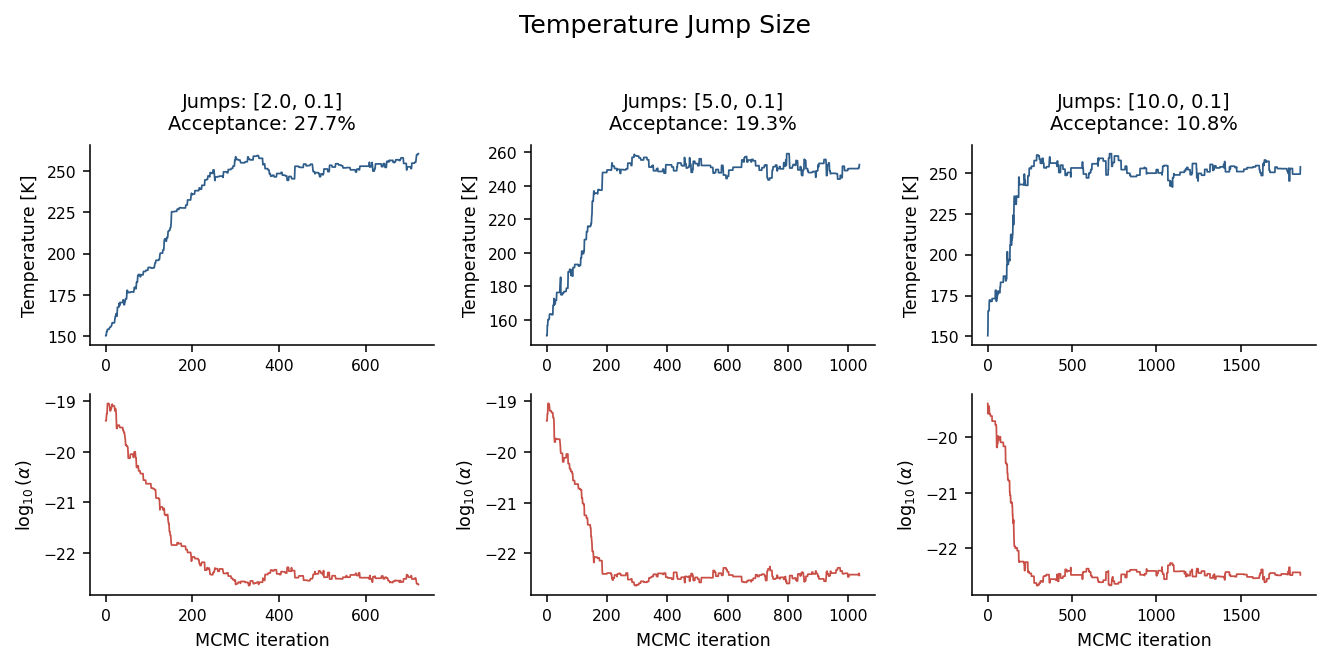

Logfactor Jump Size | Jumps: [5.0, 0.04] | Acceptance: 25.32% | Proposals: 790
Logfactor Jump Size | Jumps: [5.0, 0.1] | Acceptance: 19.29% | Proposals: 1037
Logfactor Jump Size | Jumps: [5.0, 0.2] | Acceptance: 11.51% | Proposals: 1737
Saved: graph/03_Logfactor_Jump_Size.png


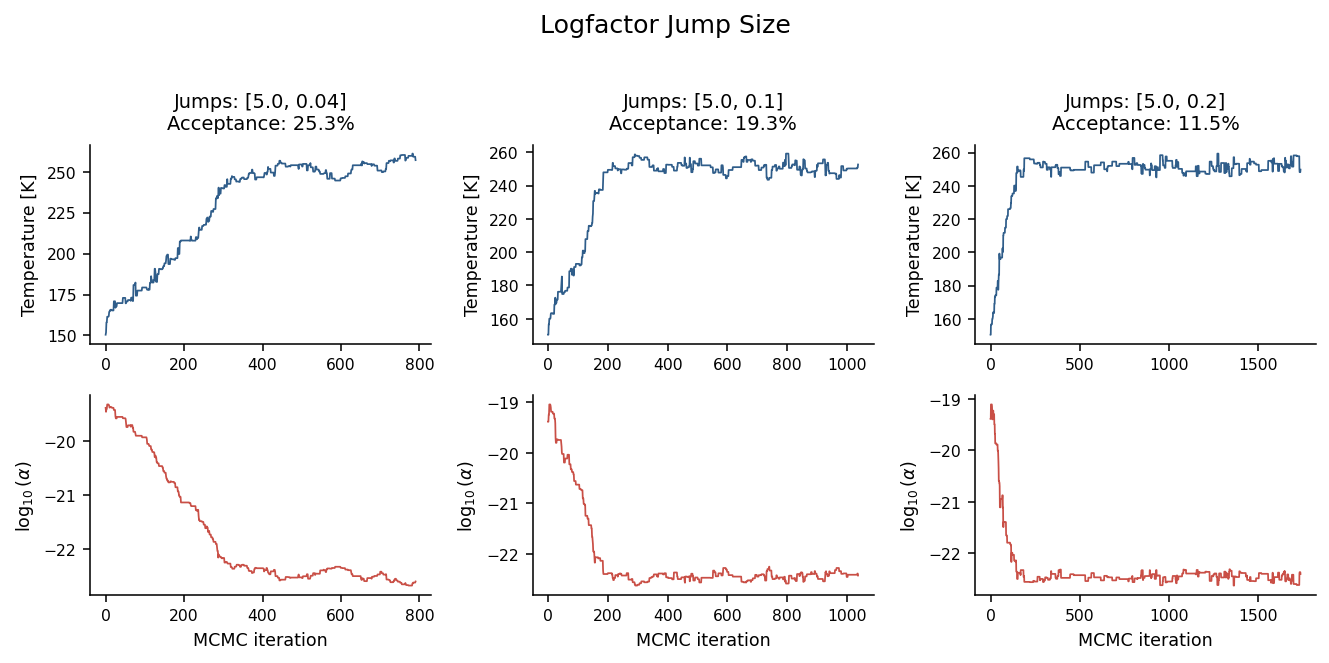

In [7]:
# Compare proposal jump sizes
jump_tests = [
    ("Temperature Jump Size", [[2.0, 0.10], [5.0, 0.10], [10.0, 0.10]]),
    ("Logfactor Jump Size", [[5.0, 0.04], [5.0, 0.10], [5.0, 0.20]])
]

jmax = 200

for title, jump_options in jump_tests:

    fig, axes = plt.subplots(2, 3, figsize=(9.6, 4.6), dpi=140)

    for i, jumpsize in enumerate(jump_options):
        np.random.seed(17)

        chain, logpost, acceptance = run_mcmc(
            theta0, lam, logf, errlogf,
            bounds, np.array(jumpsize), jmax
        )

        axes[0, i].plot(chain[:, 0], color='#2F5D8A', linewidth=0.9)
        axes[1, i].plot(chain[:, 1], color='#C94F46', linewidth=0.9)

        axes[0, i].set_title(
            f'Jumps: {jumpsize}\nAcceptance: {acceptance:.1%}',
            fontsize=10, pad=8
        )

        axes[0, i].set_ylabel('Temperature [K]', fontsize=9)
        axes[1, i].set_ylabel(r'$\log_{10}(\alpha)$', fontsize=9)
        axes[1, i].set_xlabel('MCMC iteration', fontsize=9)

        for ax in axes[:, i]:
            ax.spines['top'].set_visible(False)
            ax.spines['right'].set_visible(False)
            ax.tick_params(axis='both', labelsize=8)

        print(
            f"{title} | Jumps: {jumpsize} | "
            f"Acceptance: {acceptance:.2%} | "
            f"Proposals: {len(chain) - 1}"
        )

    fig.suptitle(title, fontsize=13, y=1.02)
    plt.tight_layout()
    plt.show()

Task 6.1: Run the longer MCMC chain

Accepted moves = 10000
Total proposals = 59784
Acceptance rate = 16.73%
Final temperature = 253.726 K
Final logfactor = -22.4497
Final log-posterior = -10.146
Saved: graph/04_Temperature_Trace.png


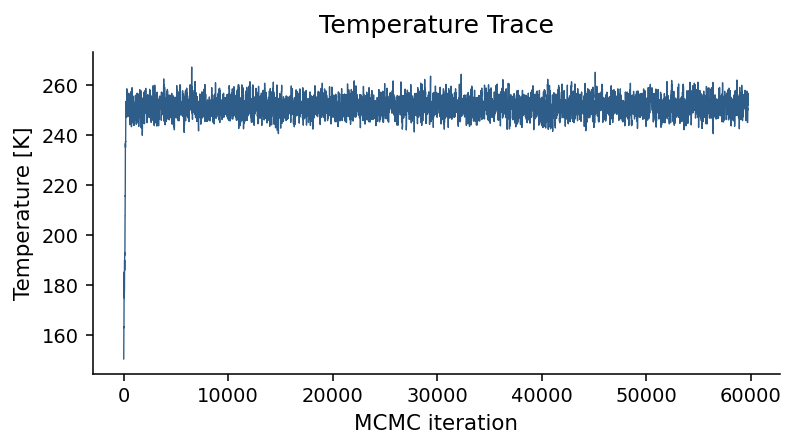

Saved: graph/05_Logfactor_Trace.png


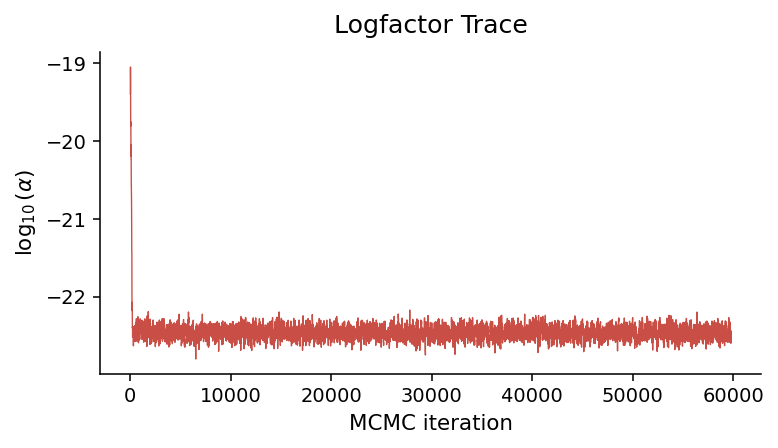

Saved: graph/06_Log_Posterior_Trace.png


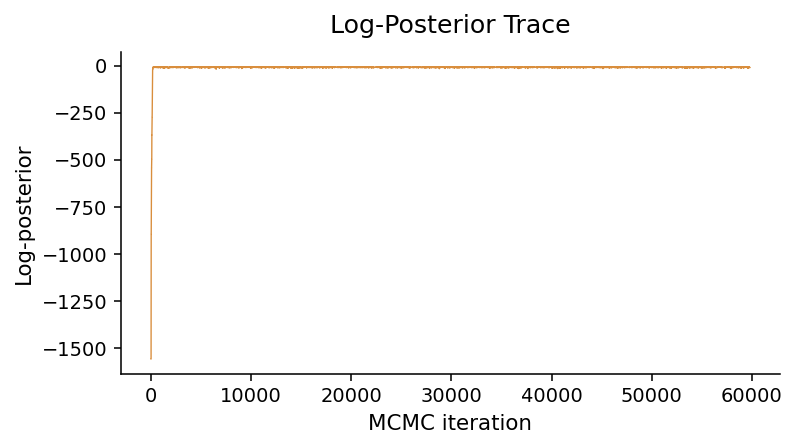

In [8]:
# Task 6.1: Run a long MCMC chain
jumpsize = np.array([5.0, 0.10])
jmax = 10000

np.random.seed(17)

thetachain, logpostchain, acceptance_rate = run_mcmc(
    theta0, lam, logf, errlogf, bounds, jumpsize, jmax
)

print(f"Accepted moves = {jmax}")
print(f"Total proposals = {len(thetachain) - 1}")
print(f"Acceptance rate = {acceptance_rate:.2%}")
print(f"Final temperature = {thetachain[-1, 0]:.3f} K")
print(f"Final logfactor = {thetachain[-1, 1]:.4f}")
print(f"Final log-posterior = {logpostchain[-1]:.3f}")


# Temperature trace
fig, ax = plt.subplots(figsize=(5.8, 3.3), dpi=140)

ax.plot(thetachain[:, 0], color='#2F5D8A', linewidth=0.7)

ax.set_xlabel('MCMC iteration', fontsize=11)
ax.set_ylabel('Temperature [K]', fontsize=11)
ax.set_title('Temperature Trace', fontsize=13, pad=10)

ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.tick_params(axis='both', labelsize=10)

plt.tight_layout()
plt.show()


# Logfactor trace
fig, ax = plt.subplots(figsize=(5.8, 3.3), dpi=140)

ax.plot(thetachain[:, 1], color='#C94F46', linewidth=0.7)

ax.set_xlabel('MCMC iteration', fontsize=11)
ax.set_ylabel(r'$\log_{10}(\alpha)$', fontsize=11)
ax.set_title('Logfactor Trace', fontsize=13, pad=10)

ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.tick_params(axis='both', labelsize=10)

plt.tight_layout()
plt.show()


# Log-posterior trace
fig, ax = plt.subplots(figsize=(5.8, 3.3), dpi=140)

ax.plot(logpostchain, color='#D98E3D', linewidth=0.7)

ax.set_xlabel('MCMC iteration', fontsize=11)
ax.set_ylabel('Log-posterior', fontsize=11)
ax.set_title('Log-Posterior Trace', fontsize=13, pad=10)

ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.tick_params(axis='both', labelsize=10)

plt.tight_layout()
plt.show()

Task 6.2: Filter out burn-in points

Median chi-squared = 5.284
Burn-in cutoff = 214
Burn-in fraction = 0.36%
Saved: graph/07_Temperature_Trace_Initial_Iterations.png


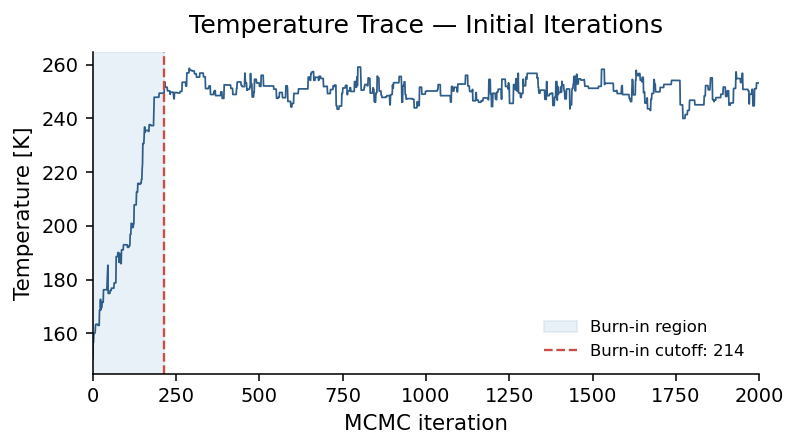

Saved: graph/08_Logfactor_Trace_Initial_Iterations.png


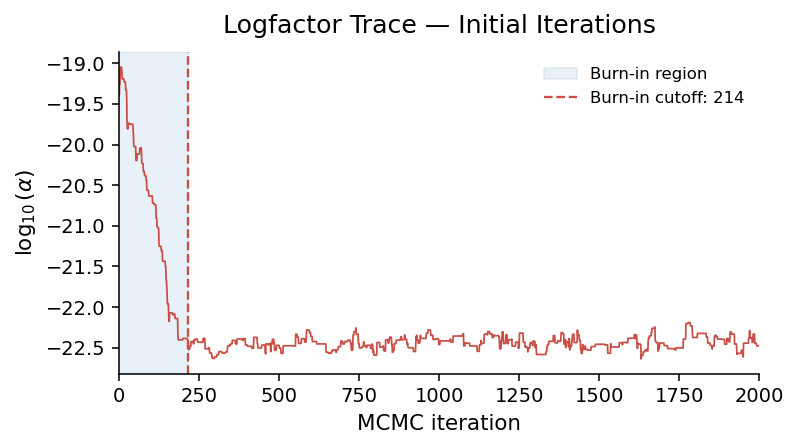

Saved: graph/09_Log_Posterior_Trace_Initial_Iterations.png


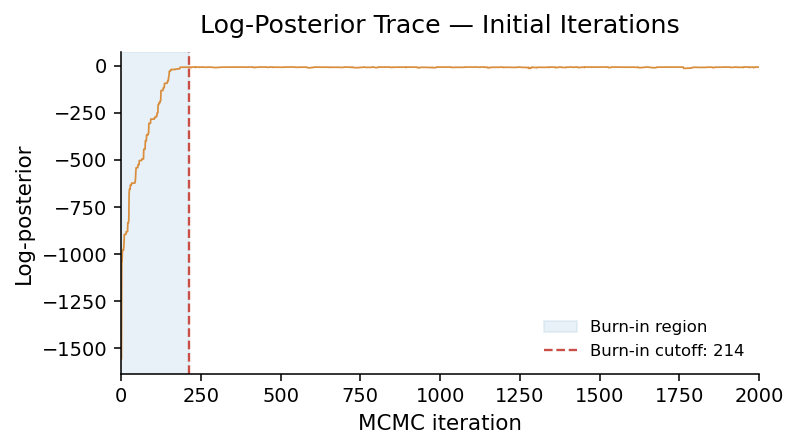

In [9]:
# Task 6.2: Identify the burn-in cutoff
chi2chain = np.array([
    chi_squared(lam, logf, errlogf, theta)
    for theta in thetachain
])

chi2_median = np.median(chi2chain)
burnj = np.where(chi2chain < chi2_median)[0][0]

print(f"Median chi-squared = {chi2_median:.3f}")
print(f"Burn-in cutoff = {burnj}")
print(f"Burn-in fraction = {burnj / len(thetachain):.2%}")

# Inspect the initial iterations
nzoom = 2000

traces = [
    (thetachain[:, 0], 'Temperature [K]', 'Temperature Trace', '#2F5D8A'),
    (thetachain[:, 1], r'$\log_{10}(\alpha)$', 'Logfactor Trace', '#C94F46'),
    (logpostchain, 'Log-posterior', 'Log-Posterior Trace', '#D98E3D')
]

for values, ylabel, title, color in traces:
    fig, ax = plt.subplots(figsize=(5.8, 3.3), dpi=140)

    # Burn-in shaded region
    ax.axvspan(
        0, burnj,
        color='#BFD7EA',
        alpha=0.35,
        label='Burn-in region'
    )

    # Trace
    ax.plot(
        values[:nzoom],
        color=color,
        linewidth=0.9
    )

    # Burn-in cutoff line
    ax.axvline(
        burnj,
        color='#C94F46',
        linestyle='--',
        linewidth=1.2,
        label=f'Burn-in cutoff: {burnj}'
    )

    ax.set_xlabel('MCMC iteration', fontsize=11)
    ax.set_ylabel(ylabel, fontsize=11)
    ax.set_title(title + ' — Initial Iterations', fontsize=13, pad=10)
    ax.set_xlim(0, nzoom)

    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.tick_params(axis='both', labelsize=10)
    ax.legend(frameon=False, fontsize=8.5)

    plt.tight_layout()
    plt.show()

Task 7.1: Prove burnt-in & good mixing

Burn-in cutoff = 214
Remaining samples = 59571
Saved: graph/10_Temperature_Trace_Post_Burn_in.png


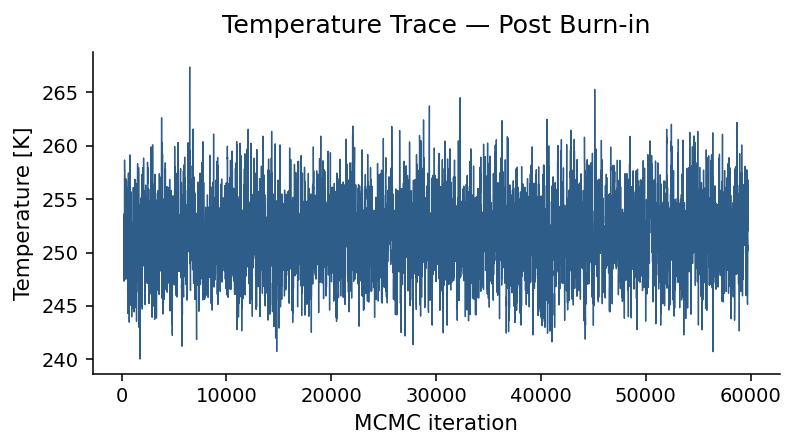

Saved: graph/11_Logfactor_Trace_Post_Burn_in.png


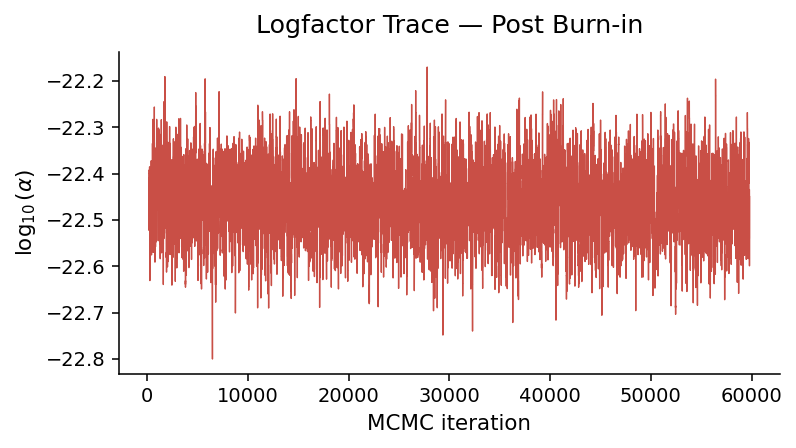

Saved: graph/12_Temperature_Running_Mean.png


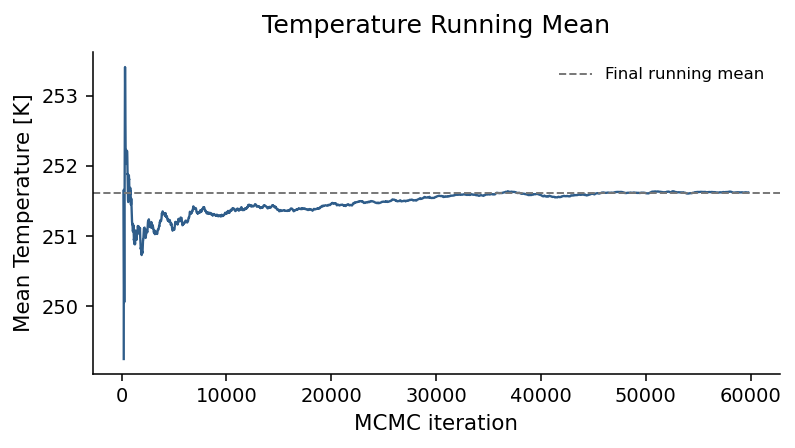

Saved: graph/13_Logfactor_Running_Mean.png


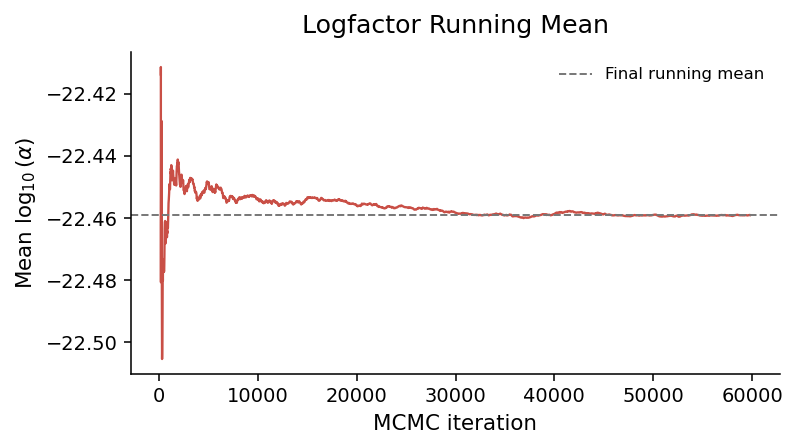

Temperature [K]: first-half mean = 251.5587, second-half mean = 251.6827
Logfactor: first-half mean = -22.4582, second-half mean = -22.4599


In [10]:
# Task 7.1: Check mixing after burn-in
post_burn = thetachain[burnj:]
steps = np.arange(burnj, len(thetachain))

print(f"Burn-in cutoff = {burnj}")
print(f"Remaining samples = {len(post_burn)}")


# Post-burn-in parameter traces
traces = [
    (post_burn[:, 0], 'Temperature [K]', 'Temperature Trace — Post Burn-in', '#2F5D8A'),
    (post_burn[:, 1], r'$\log_{10}(\alpha)$', 'Logfactor Trace — Post Burn-in', '#C94F46')
]

for values, ylabel, title, color in traces:
    fig, ax = plt.subplots(figsize=(5.8, 3.3), dpi=140)

    ax.plot(steps, values, color=color, linewidth=0.7)

    ax.set_xlabel('MCMC iteration', fontsize=11)
    ax.set_ylabel(ylabel, fontsize=11)
    ax.set_title(title, fontsize=13, pad=10)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.tick_params(axis='both', labelsize=10)

    plt.tight_layout()
    plt.show()


# Running means
running_mean_T = np.cumsum(post_burn[:, 0]) / np.arange(1, len(post_burn) + 1)
running_mean_logfactor = np.cumsum(post_burn[:, 1]) / np.arange(1, len(post_burn) + 1)

running_means = [
    (running_mean_T, 'Mean Temperature [K]', 'Temperature Running Mean', '#2F5D8A'),
    (running_mean_logfactor, r'Mean $\log_{10}(\alpha)$', 'Logfactor Running Mean', '#C94F46')
]

for values, ylabel, title, color in running_means:
    fig, ax = plt.subplots(figsize=(5.8, 3.3), dpi=140)

    ax.plot(steps, values, color=color, linewidth=1.2)
    ax.axhline(
        values[-1], color='#777777',
        linestyle='--', linewidth=1,
        label='Final running mean'
    )

    ax.set_xlabel('MCMC iteration', fontsize=11)
    ax.set_ylabel(ylabel, fontsize=11)
    ax.set_title(title, fontsize=13, pad=10)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.tick_params(axis='both', labelsize=10)
    ax.legend(frameon=False, fontsize=8.5)

    plt.tight_layout()
    plt.show()


# Compare the first and second halves of the chain
half = len(post_burn) // 2

for i, name in enumerate(['Temperature [K]', 'Logfactor']):
    first_mean = np.mean(post_burn[:half, i])
    second_mean = np.mean(post_burn[half:, i])

    print(
        f"{name}: first-half mean = {first_mean:.4f}, "
        f"second-half mean = {second_mean:.4f}"
    )


Task 7.2: Plot posterior histograms

Saved: graph/14_Temperature_Posterior.png


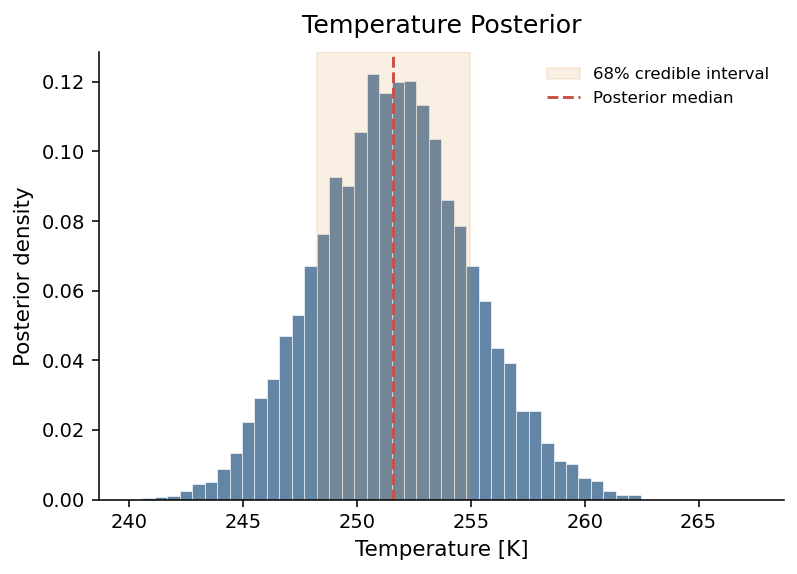

Temperature Posterior
Median = 251.5923
16th percentile = 248.2492
84th percentile = 254.9388
68% interval = 251.5923 (+3.3465, -3.3430)

Saved: graph/15_Logfactor_Posterior.png


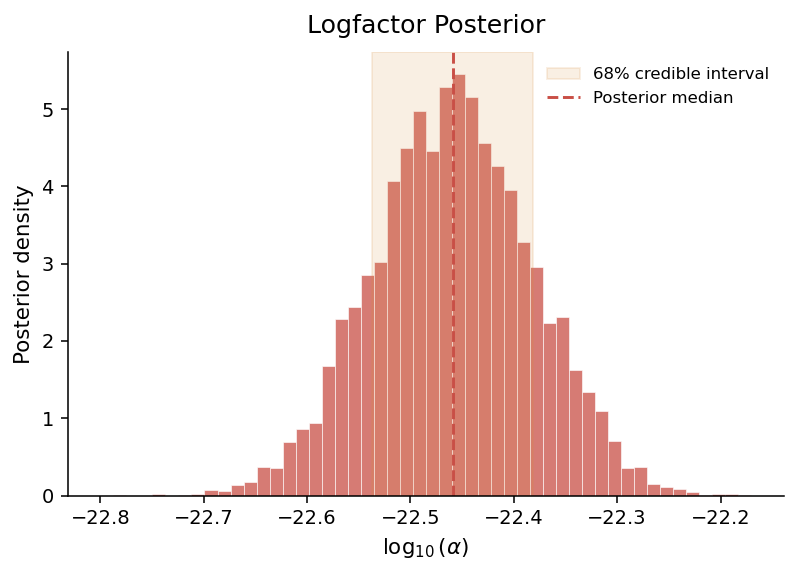

Logfactor Posterior
Median = -22.4588
16th percentile = -22.5368
84th percentile = -22.3817
68% interval = -22.4588 (+0.0771, -0.0779)



In [11]:
# Task 7.2: Posterior histograms
post_burn = thetachain[burnj:]

parameters = [
    (post_burn[:, 0], 'Temperature [K]', 'Temperature Posterior', '#2F5D8A'),
    (post_burn[:, 1], r'$\log_{10}(\alpha)$', 'Logfactor Posterior', '#C94F46')
]

for values, xlabel, title, color in parameters:
    q16, q50, q84 = np.percentile(values, [16, 50, 84])

    fig, ax = plt.subplots(figsize=(5.8, 4.2), dpi=140)

    ax.hist(
        values, bins=50, density=True,
        color=color, alpha=0.75,
        edgecolor='white', linewidth=0.4
    )

    ax.axvspan(
        q16, q84,
        color='#D98E3D', alpha=0.14,
        label='68% credible interval'
    )

    ax.axvline(
        q50, color='#C94F46',
        linestyle='--', linewidth=1.5,
        label='Posterior median'
    )

    ax.set_xlabel(xlabel, fontsize=11)
    ax.set_ylabel('Posterior density', fontsize=11)
    ax.set_title(title, fontsize=13, pad=10)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.tick_params(axis='both', labelsize=10)
    ax.legend(frameon=False, fontsize=8.5)

    plt.tight_layout()
    plt.show()

    print(f"{title}")
    print(f"Median = {q50:.4f}")
    print(f"16th percentile = {q16:.4f}")
    print(f"84th percentile = {q84:.4f}")
    print(f"68% interval = {q50:.4f} (+{q84-q50:.4f}, -{q50-q16:.4f})")
    print()

Task 8: Combine multiple chains from independent seeds

Seed 29: acceptance = 16.99%, proposals = 58860
Seed 43: acceptance = 16.89%, proposals = 59199
Seed 17: burn-in = 214, remaining samples = 59571
Seed 29: burn-in = 167, remaining samples = 58694
Seed 43: burn-in = 261, remaining samples = 58939
Saved: graph/16_Temperature_Trace_Multiple_Chains.png


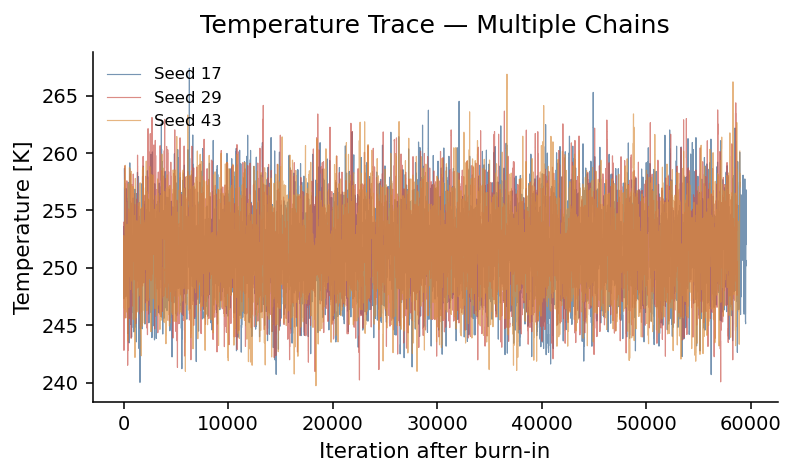

Saved: graph/17_Logfactor_Trace_Multiple_Chains.png


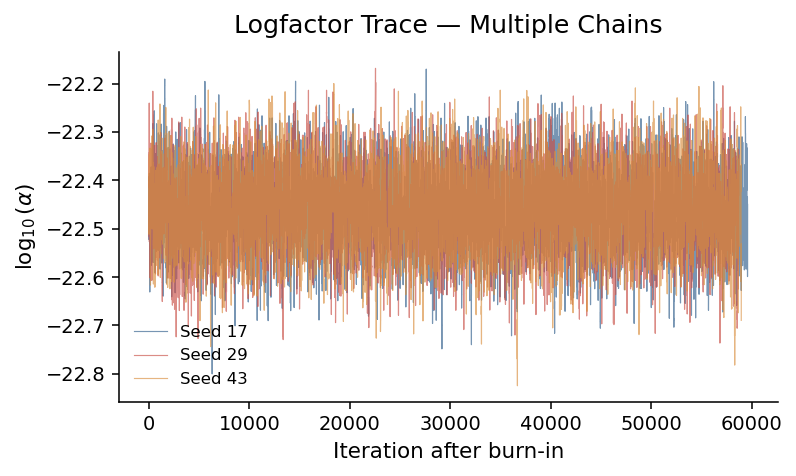

Saved: graph/18_Temperature_Posterior_Multiple_Chains.png


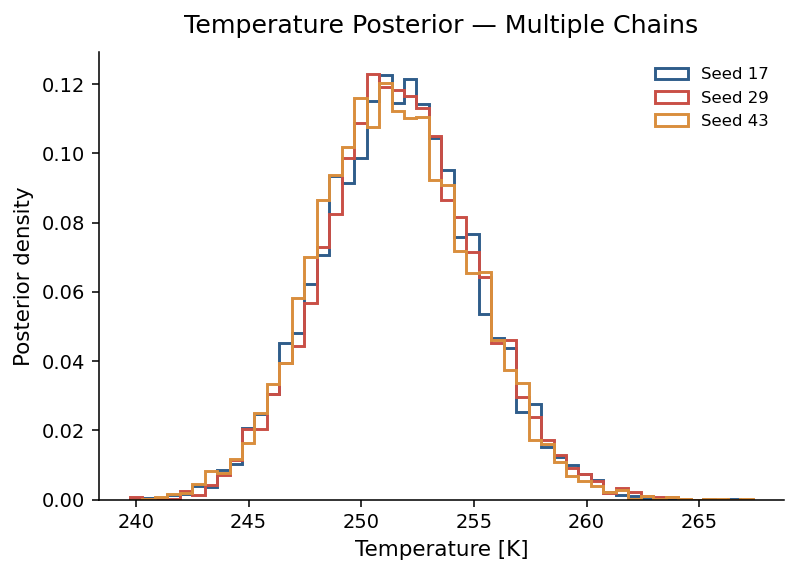

Saved: graph/19_Logfactor_Posterior_Multiple_Chains.png


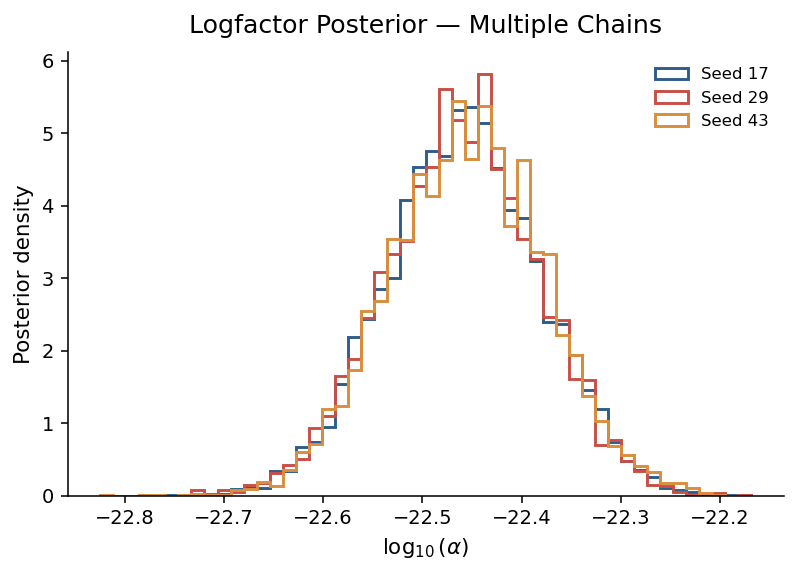

Seed 17: T = 251.592 (+3.347, -3.343) K
Seed 29: T = 251.596 (+3.480, -3.171) K
Seed 43: T = 251.343 (+3.540, -3.248) K
Combined post-burn-in samples = 177204


In [12]:
# Task 8: Compare independent MCMC chains
seeds = [29, 43]
chains = [thetachain]
labels = ['Seed 17']

jumpsize = np.array([5.0, 0.10])
jmax = 10000
colors = ['#2F5D8A', '#C94F46', '#D98E3D']

for seed in seeds:
    np.random.seed(seed)

    T0 = np.exp(np.random.uniform(np.log(Tmin), np.log(Tmax)))
    logfactor0 = np.random.uniform(logfacmin, logfacmax)
    start = np.array([T0, logfactor0])

    chain, logpost, acceptance = run_mcmc(
        start, lam, logf, errlogf, bounds, jumpsize, jmax
    )

    chains.append(chain)
    labels.append(f'Seed {seed}')

    print(
        f"Seed {seed}: acceptance = {acceptance:.2%}, "
        f"proposals = {len(chain) - 1}"
    )

# Remove burn-in separately for each chain
post_chains = []

for chain, label in zip(chains, labels):
    chi2 = np.array([
        chi_squared(lam, logf, errlogf, theta)
        for theta in chain
    ])

    cutoff = np.where(chi2 < np.median(chi2))[0][0]
    samples = chain[cutoff:]
    post_chains.append(samples)

    print(
        f"{label}: burn-in = {cutoff}, "
        f"remaining samples = {len(samples)}"
    )

parameters = [
    (0, 'Temperature [K]', 'Temperature'),
    (1, r'$\log_{10}(\alpha)$', 'Logfactor')
]

# Compare post-burn-in parameter traces
for index, ylabel, name in parameters:
    fig, ax = plt.subplots(figsize=(5.8, 3.5), dpi=140)

    for samples, label, color in zip(post_chains, labels, colors):
        ax.plot(
            np.arange(len(samples)),
            samples[:, index],
            color=color,
            linewidth=0.6,
            alpha=0.65,
            label=label
        )

    ax.set_xlabel('Iteration after burn-in', fontsize=11)
    ax.set_ylabel(ylabel, fontsize=11)
    ax.set_title(f'{name} Trace — Multiple Chains', fontsize=13, pad=10)

    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.tick_params(axis='both', labelsize=10)
    ax.legend(frameon=False, fontsize=8.5)

    plt.tight_layout()
    plt.show()

# Compare posterior distributions
for index, xlabel, name in parameters:
    fig, ax = plt.subplots(figsize=(5.8, 4.2), dpi=140)

    all_values = np.concatenate([
        samples[:, index] for samples in post_chains
    ])
    bin_edges = np.histogram_bin_edges(all_values, bins=50)

    for samples, label, color in zip(post_chains, labels, colors):
        ax.hist(
            samples[:, index],
            bins=bin_edges,
            density=True,
            histtype='step',
            linewidth=1.5,
            color=color,
            label=label
        )

    ax.set_xlabel(xlabel, fontsize=11)
    ax.set_ylabel('Posterior density', fontsize=11)
    ax.set_title(f'{name} Posterior — Multiple Chains', fontsize=13, pad=10)

    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.tick_params(axis='both', labelsize=10)
    ax.legend(frameon=False, fontsize=8.5)

    plt.tight_layout()
    plt.show()

# Compare numerical posterior summaries
for samples, label in zip(post_chains, labels):
    q16, q50, q84 = np.percentile(samples[:, 0], [16, 50, 84])

    print(
        f"{label}: T = {q50:.3f} "
        f"(+{q84-q50:.3f}, -{q50-q16:.3f}) K"
    )

# Prepare pooled samples
combined_chain = np.concatenate(post_chains, axis=0)

print(f"Combined post-burn-in samples = {len(combined_chain)}")

Task 9: Change T prior & compare

Log-uniform T
  Acceptance rate = 16.73%
  Burn-in cutoff = 214
  T = 251.592 (+3.347, -3.343) K

Uniform T
  Acceptance rate = 16.66%
  Burn-in cutoff = 214
  T = 251.498 (+3.488, -3.284) K

Uniform T^4
  Acceptance rate = 16.68%
  Burn-in cutoff = 214
  T = 251.719 (+3.337, -3.363) K

Saved: graph/20_Temperature_Trace_Prior_Comparison.png


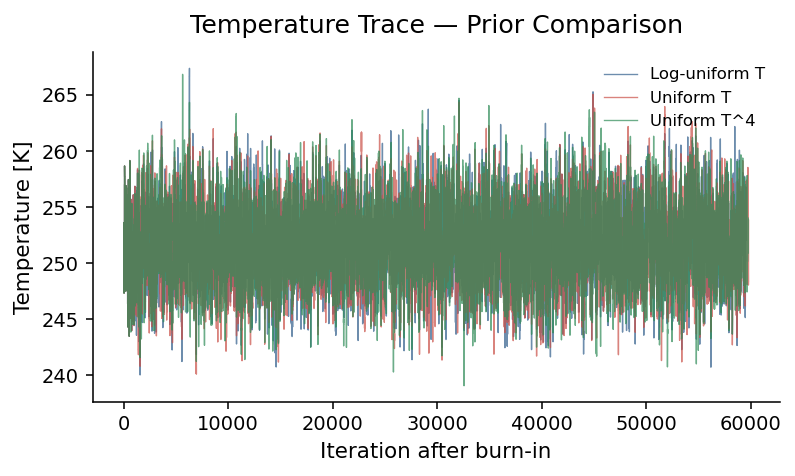

Saved: graph/21_Temperature_Posterior_Prior_Comparison.png


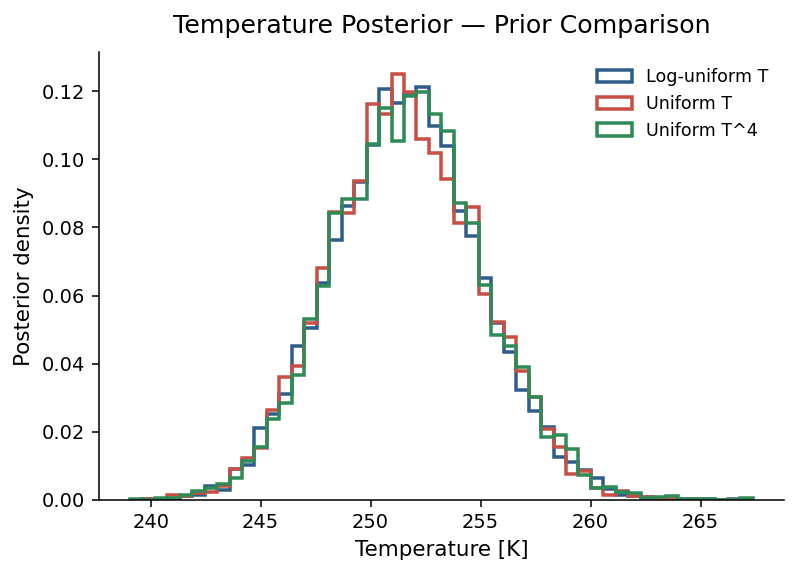

In [13]:

# Task 9: Compare different temperature priors
prior_names = ['Log-uniform T', 'Uniform T', 'Uniform T^4']
prior_colors = ['#2F5D8A', '#C94F46', '#2E8B57']

def log_posterior_with_prior(theta, prior_name):
    T, logfactor = theta

    if not (Tmin < T < Tmax and logfacmin < logfactor < logfacmax):
        return -np.inf

    if prior_name == 'Log-uniform T':
        logprior = -np.log(T)
    elif prior_name == 'Uniform T':
        logprior = 0.0
    elif prior_name == 'Uniform T^4':
        logprior = 3.0 * np.log(T)
    else:
        return -np.inf

    return logprior + log_like(lam, logf, errlogf, theta)


def run_prior_mcmc(start, prior_name, jumpsize, jmax):
    theta = np.array(start, dtype=float)
    logpost = log_posterior_with_prior(theta, prior_name)

    chain = [theta.copy()]
    accepted = 0
    proposals = 0

    while accepted < jmax:
        trial = theta + np.random.normal(0, jumpsize)
        trial_logpost = log_posterior_with_prior(trial, prior_name)

        if np.log(np.random.uniform()) < trial_logpost - logpost:
            theta = trial
            logpost = trial_logpost
            accepted += 1

        chain.append(theta.copy())
        proposals += 1

    return np.array(chain), accepted / proposals


prior_samples = []

for name in prior_names:
    np.random.seed(17)

    chain, acceptance = run_prior_mcmc(
        theta0, name, np.array([5.0, 0.10]), 10000
    )

    chi2_values = np.array([
        chi_squared(lam, logf, errlogf, theta)
        for theta in chain
    ])

    cutoff = np.where(chi2_values < np.median(chi2_values))[0][0]
    samples = chain[cutoff:]
    prior_samples.append(samples)

    q16, q50, q84 = np.percentile(samples[:, 0], [16, 50, 84])

    print(f"{name}")
    print(f"  Acceptance rate = {acceptance:.2%}")
    print(f"  Burn-in cutoff = {cutoff}")
    print(f"  T = {q50:.3f} (+{q84-q50:.3f}, -{q50-q16:.3f}) K")
    print()


# Temperature trace comparison
fig, ax = plt.subplots(figsize=(5.8, 3.5), dpi=140)

for name, samples, color in zip(prior_names, prior_samples, prior_colors):
    ax.plot(
        np.arange(len(samples)), samples[:, 0],
        color=color, linewidth=0.7,
        alpha=0.7, label=name
    )

ax.set_xlabel('Iteration after burn-in', fontsize=11)
ax.set_ylabel('Temperature [K]', fontsize=11)
ax.set_title('Temperature Trace — Prior Comparison', fontsize=13, pad=10)

ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.tick_params(axis='both', labelsize=10)
ax.legend(frameon=False, fontsize=8.5)

plt.tight_layout()
plt.show()


# Temperature posterior comparison
fig, ax = plt.subplots(figsize=(5.8, 4.2), dpi=140)

all_T = np.concatenate([samples[:, 0] for samples in prior_samples])
bins = np.histogram_bin_edges(all_T, bins=50)

for name, samples, color in zip(prior_names, prior_samples, prior_colors):
    ax.hist(
        samples[:, 0], bins=bins, density=True,
        histtype='step', linewidth=1.8,
        color=color, label=name
    )

ax.set_xlabel('Temperature [K]', fontsize=11)
ax.set_ylabel('Posterior density', fontsize=11)
ax.set_title('Temperature Posterior — Prior Comparison',
             fontsize=13, pad=10)

ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.tick_params(axis='both', labelsize=10)
ax.legend(frameon=False, fontsize=9)

plt.tight_layout()
plt.show()

Task 10: Add a quadrature extra noise term, with a log-uniform prior

Acceptance rate = 17.85%
Total proposals = 28006
Burn-in cutoff = 100
Remaining samples = 27907
Saved: graph/22_Temperature_Trace_Extra_Noise_Model.png


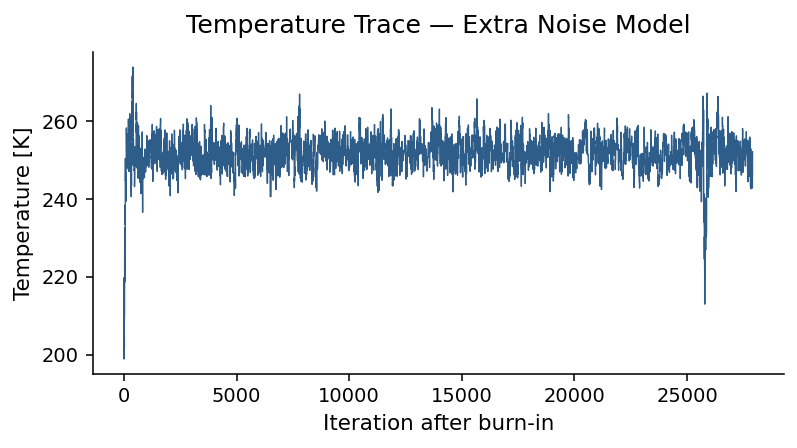

Saved: graph/23_Extra_Noise_Trace.png


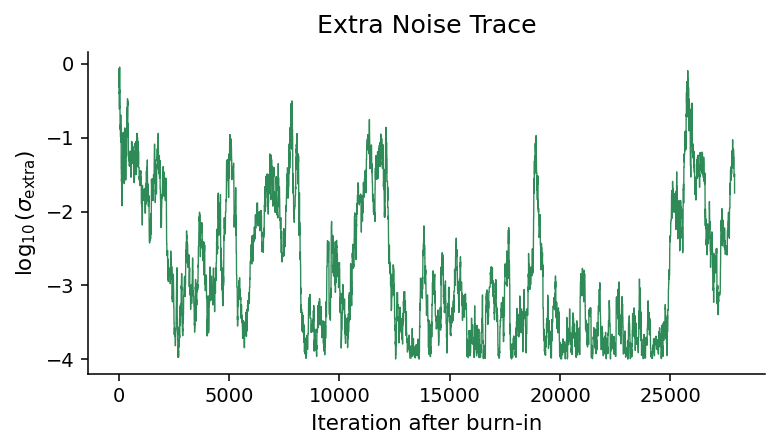

Saved: graph/24_Temperature_Posterior_Extra_Noise_Comparison.png


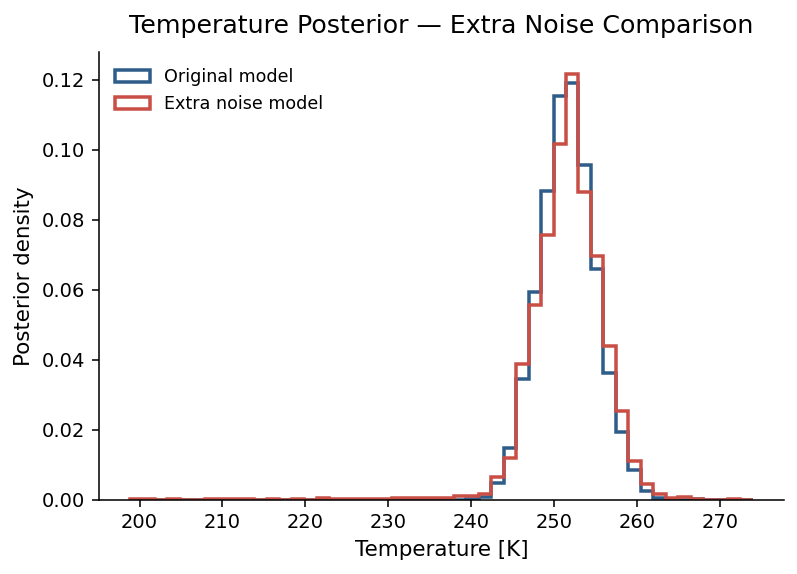

Saved: graph/25_Log_Extra_Noise_Posterior.png


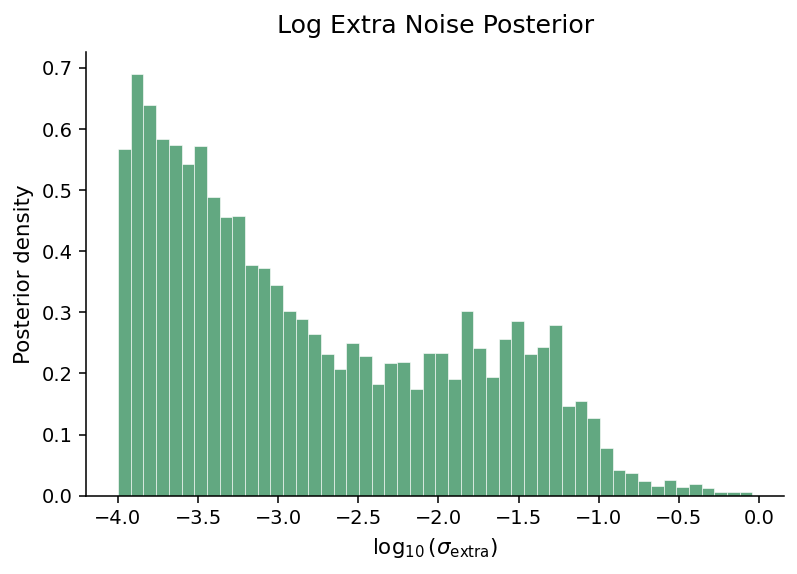

Temperature [K]: 251.8208 (+3.6369, -3.7480)
Logfactor: -22.4669 (+0.0897, -0.0781)
Extra noise [dex]: 0.0009 (+0.0226, -0.0007)


In [14]:
# Task 10: MCMC with an extra noise parameter

logsig_min, logsig_max = -4.0, 0.0

def log_posterior_noise(theta):
    T, logfactor, logsig = theta

    if not (Tmin < T < Tmax and
            logfacmin < logfactor < logfacmax and
            logsig_min < logsig < logsig_max):
        return -np.inf

    sigma_extra = 10**logsig
    variance = errlogf**2 + sigma_extra**2

    prediction = model(lam, T, logfactor)
    residual = logf - prediction

    loglike = -0.5 * np.sum(
        residual**2 / variance + np.log(2 * np.pi * variance)
    )

    logprior = -np.log(T)
    return logprior + loglike


def run_noise_mcmc(start, jumpsize, jmax):
    theta = np.array(start, dtype=float)
    logpost = log_posterior_noise(theta)

    chain = [theta.copy()]
    accepted = 0
    proposals = 0

    while accepted < jmax:
        trial = theta + np.random.normal(0, jumpsize)
        trial_logpost = log_posterior_noise(trial)

        if np.log(np.random.uniform()) < trial_logpost - logpost:
            theta = trial
            logpost = trial_logpost
            accepted += 1

        chain.append(theta.copy())
        proposals += 1

    return np.array(chain), accepted / proposals


# Run the three-parameter MCMC
np.random.seed(17)

start_noise = np.array([theta0[0], theta0[1], -1.5])
jumpsize_noise = np.array([5.0, 0.10, 0.12])

noise_chain, noise_acceptance = run_noise_mcmc(
    start_noise, jumpsize_noise, 5000
)

# Estimate burn-in
chi2_noise = np.array([
    np.sum(
        (logf - model(lam, T, logfactor))**2 /
        (errlogf**2 + 10**(2 * logsig))
    )
    for T, logfactor, logsig in noise_chain
])

noise_burnj = np.where(
    chi2_noise < np.median(chi2_noise)
)[0][0]

noise_samples = noise_chain[noise_burnj:]

print(f"Acceptance rate = {noise_acceptance:.2%}")
print(f"Total proposals = {len(noise_chain) - 1}")
print(f"Burn-in cutoff = {noise_burnj}")
print(f"Remaining samples = {len(noise_samples)}")


# Temperature trace
fig, ax = plt.subplots(figsize=(5.8, 3.3), dpi=140)

ax.plot(noise_samples[:, 0], color='#2F5D8A', linewidth=0.7)

ax.set_xlabel('Iteration after burn-in', fontsize=11)
ax.set_ylabel('Temperature [K]', fontsize=11)
ax.set_title('Temperature Trace — Extra Noise Model', fontsize=13, pad=10)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.tick_params(axis='both', labelsize=10)

plt.tight_layout()
plt.show()


# Extra noise trace
fig, ax = plt.subplots(figsize=(5.8, 3.3), dpi=140)

ax.plot(noise_samples[:, 2], color='#2E8B57', linewidth=0.7)

ax.set_xlabel('Iteration after burn-in', fontsize=11)
ax.set_ylabel(r'$\log_{10}(\sigma_{\rm extra})$', fontsize=11)
ax.set_title('Extra Noise Trace', fontsize=13, pad=10)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.tick_params(axis='both', labelsize=10)

plt.tight_layout()
plt.show()


# Compare temperature posteriors
fig, ax = plt.subplots(figsize=(5.8, 4.2), dpi=140)

original_T = thetachain[burnj:, 0]
noise_T = noise_samples[:, 0]

bins = np.histogram_bin_edges(
    np.concatenate([original_T, noise_T]), bins=50
)

ax.hist(
    original_T, bins=bins, density=True,
    histtype='step', linewidth=1.8,
    color='#2F5D8A', label='Original model'
)

ax.hist(
    noise_T, bins=bins, density=True,
    histtype='step', linewidth=1.8,
    color='#C94F46', label='Extra noise model'
)

ax.set_xlabel('Temperature [K]', fontsize=11)
ax.set_ylabel('Posterior density', fontsize=11)
ax.set_title('Temperature Posterior — Extra Noise Comparison',
             fontsize=13, pad=10)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.tick_params(axis='both', labelsize=10)
ax.legend(frameon=False, fontsize=9)

plt.tight_layout()
plt.show()


# Log extra noise posterior
logsig_samples = noise_samples[:, 2]

fig, ax = plt.subplots(figsize=(5.8, 4.2), dpi=140)

ax.hist(
    logsig_samples,
    bins=50, density=True,
    color='#2E8B57', alpha=0.75,
    edgecolor='white', linewidth=0.4
)

ax.set_xlabel(r'$\log_{10}(\sigma_{\rm extra})$', fontsize=11)
ax.set_ylabel('Posterior density', fontsize=11)
ax.set_title('Log Extra Noise Posterior', fontsize=13, pad=10)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.tick_params(axis='both', labelsize=10)

plt.tight_layout()
plt.show()


# Posterior summaries
sigma_samples = 10**logsig_samples

for name, values in [
    ('Temperature [K]', noise_samples[:, 0]),
    ('Logfactor', noise_samples[:, 1]),
    ('Extra noise [dex]', sigma_samples)
]:
    q16, q50, q84 = np.percentile(values, [16, 50, 84])

    print(
        f"{name}: {q50:.4f} "
        f"(+{q84-q50:.4f}, -{q50-q16:.4f})"
    )

Task 11: Final test

T_eff = 251.5 (+3.4, -3.3) K
log10(alpha) = -22.458 (+0.077, -0.078)
Chi-squared = 3.862
Saved: graph/26_WISE_0855_Final_Blackbody_Fit.png


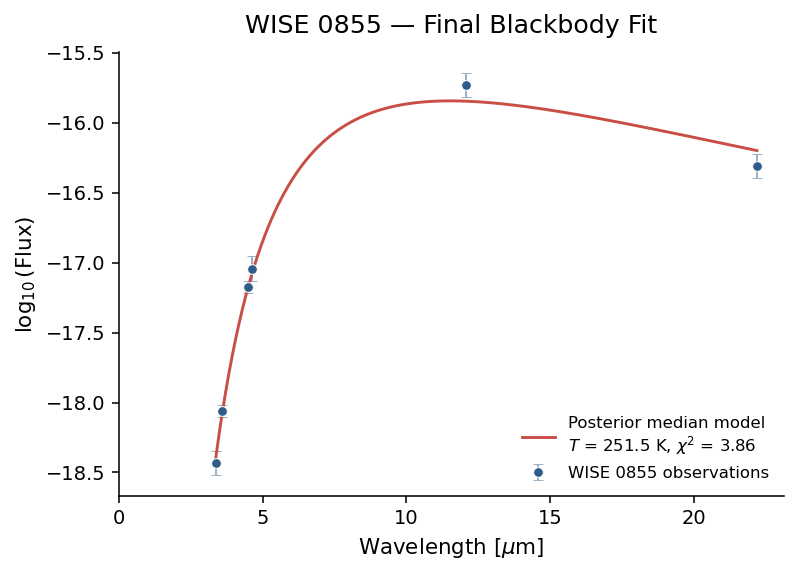

In [15]:
# Task 11: Final result — median and 1-sigma quantiles
# Use the pooled post-burn-in samples from the three seeds (Task 8)
final_T = combined_chain[:, 0]
final_logfactor = combined_chain[:, 1]

T_q16, T_q50, T_q84 = np.percentile(final_T, [16, 50, 84])
a_q16, a_q50, a_q84 = np.percentile(final_logfactor, [16, 50, 84])

print(f"T_eff = {T_q50:.1f} (+{T_q84 - T_q50:.1f}, -{T_q50 - T_q16:.1f}) K")
print(f"log10(alpha) = {a_q50:.3f} (+{a_q84 - a_q50:.3f}, -{a_q50 - a_q16:.3f})")

# Chi-squared at the posterior median parameters
theta_final = np.array([T_q50, a_q50])
chi2_final = chi_squared(lam, logf, errlogf, theta_final)

print(f"Chi-squared = {chi2_final:.3f}")

# Final blackbody model fit
lam_grid = np.linspace(lam.min(), lam.max(), 500)
model_grid = model(lam_grid, T_q50, a_q50)

fig, ax = plt.subplots(figsize=(5.8, 4.2), dpi=140)

ax.errorbar(
    lam, logf, yerr=errlogf,
    fmt='o', markersize=5,
    color='#2F5D8A',
    ecolor='#9AAFC4',
    capsize=2.5, elinewidth=1,
    markeredgecolor='white',
    markeredgewidth=0.5,
    label='WISE 0855 observations'
)

ax.plot(
    lam_grid, model_grid,
    color='#C94F46',
    linewidth=1.5,
    label=(
        f'Posterior median model\n'
        f'$T$ = {T_q50:.1f} K, '
        r'$\chi^2$' + f' = {chi2_final:.2f}'
    )
)

ax.set_xlabel(r'Wavelength [$\mu$m]', fontsize=11)
ax.set_ylabel(r'$\log_{10}(\mathrm{Flux})$', fontsize=11)
ax.set_title('WISE 0855 — Final Blackbody Fit', fontsize=13, pad=10)
ax.set_xlim(left=0)

ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.tick_params(axis='both', labelsize=10)
ax.legend(frameon=False, fontsize=8.5)

plt.tight_layout()
plt.show()